# Bài 18: Các Mô hình Sinh Ảnh (Generative Models) — VAE, GAN, Diffusion và Tổng quan Autoregressive / Flow

## 1. Mục tiêu học tập
- Phân biệt mô hình phân biệt (**Discriminative Models**: học xác suất có điều kiện $P(y \mid x)$ để dự đoán nhãn) với mô hình sinh (**Generative Models**: học phân phối dữ liệu $P(x)$ để sinh ra bức ảnh mới).
- Nắm vững nguyên lý hoạt động, kiến trúc và hàm mất mát của 4 nhánh mô hình sinh chính:
  1. **Variational Autoencoder (`VAE`)**: Không gian ẩn xác suất $(\mu, \log\sigma^2)$, thủ thuật tái tham số hóa (**`Reparameterization Trick`**) và hàm mất mát **`Reconstruction Loss + KL Divergence`**.
  2. **Generative Adversarial Networks (`GAN`)**: Trò chơi đối kháng hai người giữa **`Generator` ($G$)** và **`Discriminator` ($D$)**.
  3. **Denoising Diffusion Probabilistic Models (`Diffusion / DDPM`)**: Quá trình thuận cộng nhiễu theo lịch **`noise_schedule`** ($\beta_t$) qua các bước thời gian **`timestep`** ($t$) và quá trình ngược dùng mạng nơ-ron dự đoán nhiễu để khử nhiễu (**`denoising`**).
  4. **Tổng quan Autoregressive Image Models (`PixelCNN`, `VQ-VAE + Transformer`) & Normalizing Flows**.
- **Thực hành huấn luyện thật**: Huấn luyện một mô hình `TinyVAE` trên tập ảnh chữ số `8x8` để sinh chữ số mới bằng cách lấy mẫu từ phân phối chuẩn $\mathcal{N}(0, I)$, đồng thời minh họa trực quan chuỗi thêm nhiễu / khử nhiễu của `Diffusion`.

> **Lưu ý sư phạm**: Ví dụ trong bài được thu nhỏ về kích thước `8x8` để chạy mượt trên CPU trong vài giây nhằm minh họa chính xác cơ chế toán học. Các mô hình sinh công nghiệp (như Stable Diffusion, SDXL, Flux) có hàng tỷ tham số, đòi hỏi GPU mạnh và chỉ nên dùng ở chế độ inference hoặc fine-tune nhẹ (LoRA).

## 2. Kiến thức cần có
- Đã hoàn thành Bài 15 (`Autoencoder`).

## 3. Thời gian học dự kiến
- Khoảng **2.5 giờ** (ước tính).

## 4, 5, 6 & 7. Giải thích Trực quan, Từ điển Keyword & Công thức Toán học
1. **Thủ thuật Tái tham số hóa (`Reparameterization Trick`) và Hàm mất mát của `VAE`**:
   - Nếu lấy mẫu trực tiếp $z \sim \mathcal{N}(\mu, \sigma^2)$, bước lấy mẫu ngẫu nhiên không có đạo hàm theo $\mu, \sigma$. Ta tách phần ngẫu nhiên sang biến phụ $\epsilon \sim \mathcal{N}(0, I)$:
     $$z = \mu + \sigma \odot \epsilon, \quad \text{với } \sigma = \exp\left(\frac{1}{2} \log\sigma^2\right)$$
   - Hàm mất mát `VAE`:
     $$\mathcal{L}_{\text{VAE}} = \|x - \hat{x}\|_2^2 + \beta \cdot D_{\text{KL}}\big(\mathcal{N}(\mu, \sigma^2) \parallel \mathcal{N}(0, I)\big), \quad D_{\text{KL}} = -\frac{1}{2}\sum_{j=1}^D \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$
2. **Trò chơi Minimax của `GAN`**:
   $$\min_G \max_D \; \mathbb{E}_{x \sim p_{\text{data}}}[\log D(x)] + \mathbb{E}_{z \sim \mathcal{N}(0, I)}[\log(1 - D(G(z)))]$$
3. **Công thức thêm nhiễu trực tiếp tại bước $t$ của `Diffusion (DDPM)`**:
   Với lịch nhiễu $\beta_t \in (0, 1)$, đặt $\alpha_t = 1 - \beta_t$ và tích lũy $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$. Ta có thể nhảy thẳng từ ảnh gốc $x_0$ tới ảnh nhiễu ở bất kỳ bước $t$ nào:
   $$x_t = \sqrt{\bar{\alpha}_t}\, x_0 + \sqrt{1 - \bar{\alpha}_t}\, \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$


In [1]:
# Cell 1: Xây dựng và Huấn luyện Thực tế Mô hình Variational Autoencoder (TinyVAE) Sinh Ảnh Chữ số
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits

from src.utils import set_seed, get_device, count_parameters

QUICK_RUN = True
set_seed(42)
device = get_device()

digits = load_digits()
X_digits = torch.from_numpy(digits.data.astype(np.float32) / 16.0)  # (1797, 64) trong [0, 1]
vae_loader = DataLoader(TensorDataset(X_digits), batch_size=64, shuffle=True)


class TinyVAE(nn.Module):
    def __init__(self, input_dim: int = 64, hidden_dim: int = 48, latent_dim: int = 2) -> None:
        super().__init__()
        self.enc_fc = nn.Linear(input_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h = F.relu(self.enc_fc(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar


vae = TinyVAE(input_dim=64, hidden_dim=48, latent_dim=2).to(device)
opt_vae = torch.optim.AdamW(vae.parameters(), lr=5e-3)
epochs_vae = 20 if QUICK_RUN else 45

for ep in range(1, epochs_vae + 1):
    vae.train()
    total_recon, total_kl = 0.0, 0.0
    for (xb,) in vae_loader:
        xb = xb.to(device)
        opt_vae.zero_grad()
        recon_b, mu_b, logvar_b = vae(xb)
        recon_loss = F.mse_loss(recon_b, xb, reduction="sum") / len(xb)
        kl_loss = -0.5 * torch.sum(1.0 + logvar_b - mu_b.pow(2) - logvar_b.exp(), dim=1).mean()
        loss = recon_loss + 0.02 * kl_loss
        loss.backward()
        opt_vae.step()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

print(f"TinyVAE ({count_parameters(vae)['total']} params) hoàn tất {epochs_vae} epochs -> Recon Loss={total_recon/len(vae_loader):.4f}, KL={total_kl/len(vae_loader):.4f}")


TinyVAE (6596 params) hoàn tất 20 epochs -> Recon Loss=2.7295, KL=5.8515


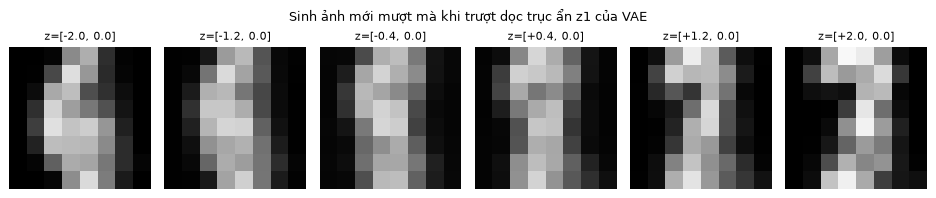

In [2]:
# Cell 2: Sinh Ảnh Mới bằng cách Nội suy Liên tục trên Mặt phẳng Latent 2D của VAE
vae.eval()
grid_pts = np.linspace(-2.0, 2.0, 6)
fig, axes = plt.subplots(1, 6, figsize=(10.5, 2.2))
with torch.no_grad():
    for i, z1_val in enumerate(grid_pts):
        z_query = torch.tensor([[float(z1_val), 0.0]], device=device)
        gen_img = vae.decoder(z_query).cpu().numpy().reshape(8, 8)
        axes[i].imshow(gen_img, cmap="gray", vmin=0, vmax=1)
        axes[i].set_title(f"z=[{z1_val:+.1f}, 0.0]", fontsize=8.5)
        axes[i].axis("off")
plt.suptitle("Sinh ảnh mới mượt mà khi trượt dọc trục ẩn z1 của VAE", fontsize=10.5)
plt.tight_layout()
plt.show()


In [3]:
# Cell 3: Minh họa Trò chơi Đối kháng GAN (Generator vs Discriminator) trên Phân phối Đặc trưng
set_seed(42)
generator = nn.Sequential(nn.Linear(8, 24), nn.LeakyReLU(0.2), nn.Linear(24, 64), nn.Sigmoid()).to(device)
discriminator = nn.Sequential(nn.Linear(64, 24), nn.LeakyReLU(0.2), nn.Linear(24, 1)).to(device)  # Trả logits cho BCEWithLogitsLoss

opt_g = torch.optim.Adam(generator.parameters(), lr=2e-3, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(discriminator.parameters(), lr=2e-3, betas=(0.5, 0.999))
bce_gan = nn.BCEWithLogitsLoss()

real_batch = X_digits[:64].to(device)
for step in range(25):
    # 1. Cập nhật Discriminator D: Phân biệt ảnh thật (nhãn 1) và ảnh giả G(z) (nhãn 0)
    opt_d.zero_grad()
    z_noise = torch.randn(64, 8, device=device)
    fake_batch = generator(z_noise)
    loss_d_real = bce_gan(discriminator(real_batch), torch.ones(64, 1, device=device))
    loss_d_fake = bce_gan(discriminator(fake_batch.detach()), torch.zeros(64, 1, device=device))
    loss_d = 0.5 * (loss_d_real + loss_d_fake)
    loss_d.backward()
    opt_d.step()

    # 2. Cập nhật Generator G: Đánh lừa D để D chấm ảnh giả là nhãn 1!
    opt_g.zero_grad()
    loss_g = bce_gan(discriminator(fake_batch), torch.ones(64, 1, device=device))
    loss_g.backward()
    opt_g.step()

print(f"[GAN Minimax Demo] Sau 25 bước cập nhật đối kháng -> D_Loss: {loss_d.item():.4f} | G_Loss: {loss_g.item():.4f}")


[GAN Minimax Demo] Sau 25 bước cập nhật đối kháng -> D_Loss: 0.3368 | G_Loss: 1.3694


[Diffusion Denoiser] MSE dự đoán nhiễu ε(x_t, t) sau 40 bước: 0.4568


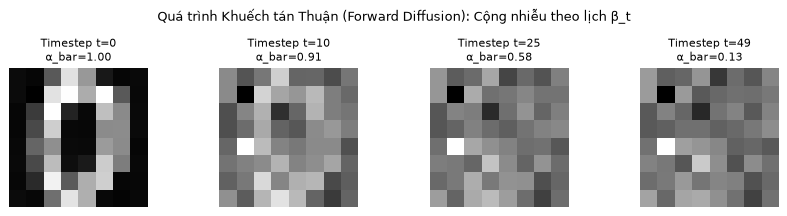

In [4]:
# Cell 4: Minh họa Cơ chế Mô hình Khuếch tán (Diffusion Models: Noise Schedule, Timestep & Denoising)
T_steps = 50
betas = torch.linspace(1e-4, 0.08, T_steps, device=device)  # Lịch nhiễu tăng tuyến tính (Linear Noise Schedule)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)


def q_sample_forward_diffusion(x0: torch.Tensor, t_idx: torch.Tensor, noise: torch.Tensor) -> torch.Tensor:
    """Công thức đóng nhảy thẳng từ ảnh sạch x0 tới ảnh nhiễu x_t tại bước thời gian t."""
    a_bar = alpha_bars[t_idx].view(-1, 1)
    return torch.sqrt(a_bar) * x0 + torch.sqrt(1.0 - a_bar) * noise


# Minh họa quá trình thuận thêm nhiễu vào ảnh chữ số tại t = 0, 10, 25, 49
x0_sample = X_digits[0:1].to(device)
eps_fixed = torch.randn_like(x0_sample)
timesteps_to_show = [0, 10, 25, 49]

fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.4))
for ax, t_val in zip(axes, timesteps_to_show):
    xt = q_sample_forward_diffusion(x0_sample, torch.tensor([t_val], device=device), eps_fixed)
    ax.imshow(xt.cpu().numpy().reshape(8, 8), cmap="gray")
    ax.set_title(f"Timestep t={t_val}\nα_bar={alpha_bars[t_val].item():.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Quá trình Khuếch tán Thuận (Forward Diffusion): Cộng nhiễu theo lịch β_t", fontsize=10.5)
plt.tight_layout()
plt.show()

# Huấn luyện mạng Denoiser nhỏ dự đoán nhiễu epsilon từ (x_t, t_normalized)
denoiser_net = nn.Sequential(nn.Linear(64 + 1, 64), nn.SiLU(), nn.Linear(64, 64)).to(device)
opt_diff = torch.optim.AdamW(denoiser_net.parameters(), lr=5e-3)
x_train_diff = X_digits[:256].to(device)

for _ in range(40):
    opt_diff.zero_grad()
    t_rand = torch.randint(0, T_steps, (len(x_train_diff),), device=device)
    noise_gt = torch.randn_like(x_train_diff)
    x_noisy = q_sample_forward_diffusion(x_train_diff, t_rand, noise_gt)
    t_feat = (t_rand.float() / T_steps).unsqueeze(1)
    noise_pred = denoiser_net(torch.cat([x_noisy, t_feat], dim=1))
    loss_diff = F.mse_loss(noise_pred, noise_gt)
    loss_diff.backward()
    opt_diff.step()

print(f"[Diffusion Denoiser] MSE dự đoán nhiễu ε(x_t, t) sau 40 bước: {loss_diff.item():.4f}")


## 11. Nhận xét cách đọc kết quả
- **Ở `VAE` (Cell 1 & 2)**: Nhờ thành phần phạt phân kỳ `KL Divergence` kéo các đám mây ẩn về gần phân phối chuẩn $\mathcal{N}(0, I)$, khi ta dịch chuyển tọa độ $z_1$ từ `-2.0` sang `+2.0`, hình ảnh sinh ra biến đổi liên tục và mượt mà (không có "hố đen" vô nghĩa như Autoencoder thường).
- **Ở `GAN` (Cell 3)**: Lưu ý kỹ thuật quan trọng khi cập nhật `Discriminator` ($D$): ta phải gọi **`fake_batch.detach()`** để ngắt đồ thị tính đạo hàm không cho chảy ngược vào `Generator` ($G$) trong bước của $D$. Khi đến lượt cập nhật $G$, ta mới truyền `fake_batch` (không detach) qua $D$ với nhãn mục tiêu là `1` (đánh lừa $D$ rằng ảnh giả là thật).
- **Ở `Diffusion` (Cell 4)**: Khi bước thời gian $t$ tăng từ `0` lên `49`, hệ số giữ tín hiệu gốc $\bar{\alpha}_t$ giảm từ `1.00` về gần `0.00`, biến bức ảnh thành nhiễu Gaussian thuần túy. Mạng khử nhiễu học cách dự đoán đúng lượng nhiễu $\epsilon$ đã cộng vào để khôi phục ngược lại bức ảnh.

## 14. Bài tập tự làm
- **Cơ bản**: Trong hàm mất mát `VAE`, thử đặt hệ số $\beta$ của `KL Divergence` bằng `0.0` (tắt hoàn toàn KL) và kiểm tra xem độ lớn trung bình của `mu` và độ lệch chuẩn `exp(0.5 * logvar)` thay đổi thế nào.
- **Trung cấp**: Viết công thức khôi phục ước lượng ảnh gốc $\hat{x}_0$ từ ảnh nhiễu $x_t$ và nhiễu dự đoán $\hat{\epsilon}_\theta(x_t, t)$ trong Diffusion: $\hat{x}_0 = \frac{x_t - \sqrt{1 - \bar{\alpha}_t}\,\hat{\epsilon}_\theta}{\sqrt{\bar{\alpha}_t}}$.
- **Nâng cao**: Giải thích hiện tượng **Mode Collapse (Sụp đổ chế độ)** trong GAN và cách phát hiện nó bằng cách đo độ lệch chuẩn giữa các ảnh sinh ra từ các vector nhiễu $z$ khác nhau.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 18
# 1. Cơ bản: Kiểm tra phân phối mu, std của VAE đã huấn luyện
with torch.no_grad():
    mu_all, logvar_all = vae.encode(X_digits[:200].to(device))
    print(f"[Cơ bản] Latent mu mean={mu_all.mean().item():.3f}, std(z)={torch.exp(0.5*logvar_all).mean().item():.3f}")

# 2. Trung cấp: Khôi phục ước lượng x0_hat từ x_t và nhiễu dự đoán trong Diffusion
with torch.no_grad():
    t_test = torch.tensor([15], device=device)
    xt_test = q_sample_forward_diffusion(x0_sample, t_test, eps_fixed)
    eps_hat = denoiser_net(torch.cat([xt_test, (t_test.float() / T_steps).unsqueeze(1)], dim=1))
    a_bar_t = alpha_bars[t_test].view(-1, 1)
    x0_hat = ((xt_test - torch.sqrt(1.0 - a_bar_t) * eps_hat) / torch.sqrt(a_bar_t)).clamp(0.0, 1.0)
    print(f"[Trung cấp] MSE trước khử nhiễu={F.mse_loss(xt_test, x0_sample).item():.4f} -> Sau khử nhiễu={F.mse_loss(x0_hat, x0_sample).item():.4f}")

# 3. Nâng cao: Hàm kiểm tra triệu chứng Mode Collapse của Generator
with torch.no_grad():
    z_diverse = torch.randn(32, 8, device=device)
    gen_samples = generator(z_diverse)
    pixel_diversity_std = gen_samples.std(dim=0).mean().item()
    print(f"[Nâng cao] Độ đa dạng giữa 32 ảnh sinh từ Generator (std across batch): {pixel_diversity_std:.4f} (Nếu ~0.0 là bị Mode Collapse!)")


[Cơ bản] Latent mu mean=-0.462, std(z)=0.104
[Trung cấp] MSE trước khử nhiễu=0.1847 -> Sau khử nhiễu=0.0744
[Nâng cao] Độ đa dạng giữa 32 ảnh sinh từ Generator (std across batch): 0.0706 (Nếu ~0.0 là bị Mode Collapse!)


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu rõ cơ chế sinh ảnh của `VAE`, `GAN` và `Diffusion Models`.
- [x] Sẵn sàng chuyển sang **Bài 19: `19_ocr_and_visual_tasks_overview.ipynb`** để khám phá `OCR`, `Pose Estimation`, `Tracking`, `Super-Resolution` và `Depth Estimation`!

## 17. Nguồn tham khảo
- Kingma, D. P., & Welling, M. (2014), *Auto-Encoding Variational Bayes (VAE)*, ICLR.
- Goodfellow, I. et al. (2014), *Generative Adversarial Nets (GAN)*, NeurIPS.
- Ho, J., Jain, A., & Abbeel, P. (2020), *Denoising Diffusion Probabilistic Models (DDPM)*, NeurIPS.
